# Apriori 關聯規則學習



## 是關聯規則學習 (Association Rule Learning)

關聯規則學習是一種非監督式學習 (Unsupervised Learning)，主要用來找出資料中經常一起出現的項目，以及項目之間的關聯。

最經典的例子就是超市購物籃分析 (Market Basket Analysis)。

假設某間超市發現：

- 購買麵包的顧客，經常也會購買牛奶。
- 購買尿布的顧客，可能也會購買啤酒。
- 購買咖啡的顧客，經常同時購買餅乾。

超市可以利用這些資訊，調整商品陳列位置、規劃促銷組合，或建立商品推薦系統。

關聯規則的基本形式：

$$\boxed{A \rightarrow B} $$

其中：

| 符號    | 名稱               | 說明               |
| ----- | ---------------- | ---------------- |
| A     | Antecedent (前件)  | 規則左側的商品或商品組合     |
| B     | Consequent (後件)  | 規則右側的商品或商品組合     |
| A → B | Association Rule | 購買 A 與購買 B 之間的關聯 |

例如：

$$ \text{麵包}\rightarrow\text{牛奶} $$

代表購買麵包的交易中，有一定比例也包含牛奶。

但要注意，關聯不等於因果。Apriori 無法證明購買麵包會導致顧客購買牛奶，也不代表顧客一定先買麵包、再買牛奶。


### Apriori 與一般機器學習的差別

| 比較項目        | Classification | Regression  | Apriori                 |
| ----------- | -------------- | ----------- | ----------------------- |
| 學習類型        | 監督式            | 監督式         | 非監督式                    |
| 是否需要 Target | 需要             | 需要          | 不需要                     |
| 主要任務        | 預測類別           | 預測數值        | 尋找商品關聯                  |
| 典型輸出        | 0、1            | 房價、AQI      | 麵包 → 牛奶                 |
| 常見評估        | Accuracy、F1    | MAE、RMSE、R² | Support、Confidence、Lift |

這裡要調整一下過去教材的實作流程。

Apriori 並不是使用 `fit()` 訓練後，再用 `predict()` 預測答案的演算法。它直接從交易資料中挖掘頻繁項目集，再產生關聯規則。因此，教材不會硬套 Train / Test Split，而是改成更適合 Apriori 的完整分析流程。

## Apriori 的運作原理

Apriori 的主要任務是：「找出經常一起出現的商品組合 (Frequent Itemsets)。」

![](./assets/Apriori.png)

## Support (支持度)

![](./assets/Support.png)


## Confidence (信賴度)

![](./assets/Confidence.png)

## Lift (提升度)

![](./assets/Lift.png)

### Support、Confidence、Lift 比較

| 指標         | 想回答的問題                 | 判讀重點 |
| ---------- | ---------------------- | ---- |
| Support    | 這個商品組合常不常出現？           | 出現頻率 |
| Confidence | 有 A 時，有多常同時出現 B？       | 條件比例 |
| Lift       | A 和 B 是否比隨機獨立情況更常一起出現？ | 關聯強度 |

## 實作：Apriori預測

### 資料集介紹

- 交易筆數1,000
- 商品種類20
- 資料列數3,905

### 欄位說明：

| 欄位             | 資料類型 | 說明          |
| -------------- | ---- | ----------- |
| transaction_id | str  | 每一筆購物交易的編號  |
| item           | str  | 該筆交易購買的商品名稱 |

相同 `transaction_id` 代表同一筆購物交易，可能對應多個商品。例如 T0001 購買了麵包、牛奶、雞蛋，代表這三個商品出現在同一個購物籃中。

### 讀取資料集

In [1]:
import pandas as pd


### 讀取超市交易資料
df = pd.read_csv("./data/apriori_supermarket_transactions.csv")


### 查看前 10 筆資料
print(df.head(10))


### 查看資料基本資訊
print(df.info())


### 查看資料統計
print(df.describe(include="all"))


### 查看資料形狀
print("資料形狀：", df.shape)

  transaction_id item
0          T0001   優格
1          T0001  洗衣精
2          T0001   牛奶
3          T0001   飲料
4          T0001   麥片
5          T0002   餅乾
6          T0003  洗衣精
7          T0003   牛奶
8          T0004   咖啡
9          T0004   泡麵
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3905 entries, 0 to 3904
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  3905 non-null   object
 1   item            3905 non-null   object
dtypes: object(2)
memory usage: 61.1+ KB
None
       transaction_id  item
count            3905  3905
unique           1000    20
top             T0733    牛奶
freq               11   491
資料形狀： (3905, 2)


### 探索資料 (EDA)

- nunique()：計算不重複的數量。
- value_counts()：計算每個商品出現幾次。
- groupby()：依照交易編號分組。

In [2]:
### 查看交易總數
transaction_count = df["transaction_id"].nunique()

print("交易總數：", transaction_count)


### 查看商品種類數量
item_count = df["item"].nunique()

print("商品種類：", item_count)


### 統計各商品出現次數
item_counts = df["item"].value_counts()

print("\n商品出現次數：")
print(item_counts)


### 統計每筆交易包含多少商品
basket_sizes = df.groupby("transaction_id")["item"].nunique()

print("\n每筆交易商品數量：")
print(basket_sizes.describe())

交易總數： 1000
商品種類： 20

商品出現次數：
item
牛奶     491
麵包     326
雞蛋     307
咖啡     254
奶油     245
泡麵     235
蘋果     219
餅乾     192
茶葉     188
飲料     173
麥片     172
洗衣精    168
尿布     165
起司     140
濕紙巾    140
優格     121
洋芋片    116
香蕉     112
火腿     111
衛生紙     30
Name: count, dtype: int64

每筆交易商品數量：
count    1000.000000
mean        3.905000
std         2.168104
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        11.000000
Name: item, dtype: float64


### 資料清理
Apriori 不需要標準化數值，但必須確保商品名稱正確，且同一筆交易不會重複計算相同商品。

In [3]:
### 移除交易編號或商品名稱缺失的資料
df = df.dropna(subset=["transaction_id", "item"]).copy()


### 統一資料型態
df["transaction_id"] = df["transaction_id"].astype(str)
df["item"] = df["item"].astype(str)


### 移除文字前後空白
df["transaction_id"] = df["transaction_id"].str.strip()
df["item"] = df["item"].str.strip()


### 排除空字串
df = df[
    (df["transaction_id"] != "") &
    (df["item"] != "")
].copy()


### 移除同一筆交易內重複出現的商品
df = df.drop_duplicates(
    subset=["transaction_id", "item"]
)


### 重設索引
df = df.reset_index(drop=True)


### 確認清理結果
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3905 entries, 0 to 3904
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  3905 non-null   object
 1   item            3905 non-null   object
dtypes: object(2)
memory usage: 61.1+ KB
None
  transaction_id item
0          T0001   優格
1          T0001  洗衣精
2          T0001   牛奶
3          T0001   飲料
4          T0001   麥片


### 選擇 Features 與 Target

Apriori 屬於非監督式學習，因此不需要 Target (y)。

| 角色     | 欄位             | 用途              |
| ------ | -------------- | --------------- |
| 交易識別   | transaction_id | 將商品歸入同一筆交易      |
| 分析項目   | item           | 尋找商品組合          |
| Target | 無              | Apriori 不需要答案欄位 |

這與 Logistic Regression、Random Forest 等監督式學習不同。

### 轉換成 One-Hot Encoding

同時，Apriori 不能直接使用原始的長格式交易資料。我們需要把資料轉換成「**每一列代表一筆交易，每一欄代表一種商品。**」

例如：

| 交易編號 | 麵包    | 牛奶   | 雞蛋    | 咖啡    |
| ---- | ----- | ---- | ----- | ----- |
| T001 | True  | True | True  | False |
| T002 | True  | True | False | False |
| T003 | False | True | False | True  |

`True` 代表有購買，`False` 代表沒有購買。


In [4]:
### 將交易資料轉換成 One-Hot Encoding
basket = pd.crosstab( # 用來統計每筆交易是否包含某個商品
    df["transaction_id"],
    df["item"]
)


### 將商品購買次數轉成布林值
basket = basket.gt(0)


### 查看轉換結果
display(basket.head())


### 查看資料形狀
print("購物籃矩陣形狀：", basket.shape)

item,優格,咖啡,奶油,尿布,泡麵,洋芋片,洗衣精,濕紙巾,火腿,牛奶,茶葉,蘋果,衛生紙,起司,雞蛋,飲料,餅乾,香蕉,麥片,麵包
transaction_id,,,,,,,,,,,,,,,,,,,,
T0001,True,False,False,False,False,False,True,False,False,True,False,False,False,False,False,True,False,False,True,False
T0002,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
T0003,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False
T0004,False,True,False,False,True,False,True,False,False,False,False,False,False,False,False,True,True,False,False,False
T0005,False,False,False,False,True,True,False,False,False,False,False,False,False,False,True,True,False,False,False,False


購物籃矩陣形狀： (1000, 20)


### 建立 Apriori 模型

In [5]:
from mlxtend.frequent_patterns import apriori


### 尋找頻繁項目集
frequent_itemsets = apriori(
    basket,
    min_support=0.05, # 商品組合至少出現在 5% 的交易中
    use_colnames=True, # 顯示商品名稱，而不是欄位索引
    max_len=3,         # 最多尋找 3 個商品的組合
    low_memory=False   # 使用一般記憶體模式
)


### 依照 Support 由大到小排序
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)


### 查看結果
print(frequent_itemsets.head(20))


### 查看頻繁項目集總數
print("頻繁項目集數量：", len(frequent_itemsets))

    support      itemsets
0     0.491          (牛奶)
1     0.326          (麵包)
2     0.307          (雞蛋)
3     0.254          (咖啡)
4     0.245          (奶油)
5     0.235          (泡麵)
6     0.225      (奶油, 麵包)
7     0.222      (麵包, 牛奶)
8     0.219          (蘋果)
9     0.192          (餅乾)
10    0.188          (茶葉)
11    0.173          (飲料)
12    0.172          (麥片)
13    0.170      (奶油, 牛奶)
14    0.168         (洗衣精)
15    0.167      (咖啡, 餅乾)
16    0.165          (尿布)
17    0.161  (奶油, 麵包, 牛奶)
18    0.146      (飲料, 泡麵)
19    0.144      (雞蛋, 牛奶)
頻繁項目集數量： 84


### 產生 Association Rules

找到頻繁項目集之後，才能產生關聯規則。

In [7]:
from mlxtend.frequent_patterns import association_rules


### 根據頻繁項目集產生關聯規則
rules = association_rules(
    frequent_itemsets,
    metric="confidence", # 使用 Confidence 作為篩選標準
    min_threshold=0.5,    # 只保留 Confidence >= 50% 的規則
    num_itemsets=len(basket) # 提供原始交易總數
)


### 依照 Lift 由大到小排序
rules = rules.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)


### 查看重要指標
result = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()


### 顯示前 20 筆
display(result.head(20))

,antecedents,consequents,support,confidence,lift
0,"(尿布, 牛奶)",(濕紙巾),0.061,0.743902,5.313589
1,(尿布),(濕紙巾),0.114,0.690909,4.935065
2,(濕紙巾),(尿布),0.114,0.814286,4.935065
3,(麥片),(優格),0.102,0.593023,4.901019
4,(優格),(麥片),0.102,0.842975,4.901019
5,"(濕紙巾, 牛奶)",(尿布),0.061,0.802632,4.864434
6,"(飲料, 洋芋片)",(泡麵),0.052,1.000000,4.255319
7,"(咖啡, 雞蛋)",(餅乾),0.056,0.777778,4.050926
8,"(餅乾, 牛奶)",(咖啡),0.077,0.927711,3.652405
9,(飲料),(泡麵),0.146,0.843931,3.591194


### 篩選有價值的關聯規則

假設我們希望找出：
- Support 至少 5%。
- Confidence 至少 50%。
- Lift 大於 1。

這三個條件各自扮演不同角色：
- Support 排除出現次數太少的組合；
- Confidence 確認條件比例夠高；
- Lift 則確認商品之間存在正向關聯。

In [9]:
### 篩選有正向關聯的規則
filtered_rules = rules[
    (rules["support"] >= 0.05) &
    (rules["confidence"] >= 0.5) &
    (rules["lift"] > 1)
].copy()


### 依照 Lift 排序
filtered_rules = filtered_rules.sort_values(
    by="lift",
    ascending=False
).reset_index(drop=True)


### 查看結果
display(
    filtered_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(20)
)

,antecedents,consequents,support,confidence,lift
0,"(尿布, 牛奶)",(濕紙巾),0.061,0.743902,5.313589
1,(尿布),(濕紙巾),0.114,0.690909,4.935065
2,(濕紙巾),(尿布),0.114,0.814286,4.935065
3,(麥片),(優格),0.102,0.593023,4.901019
4,(優格),(麥片),0.102,0.842975,4.901019
5,"(濕紙巾, 牛奶)",(尿布),0.061,0.802632,4.864434
6,"(飲料, 洋芋片)",(泡麵),0.052,1.000000,4.255319
7,"(咖啡, 雞蛋)",(餅乾),0.056,0.777778,4.050926
8,"(餅乾, 牛奶)",(咖啡),0.077,0.927711,3.652405
9,(飲料),(泡麵),0.146,0.843931,3.591194


### 視覺化關聯規則

教材建議使用三種圖表：
1. 商品購買次數長條圖。
2. Top 10 Lift 關聯規則長條圖。

#### 商品購買次數 (Bar Chart)

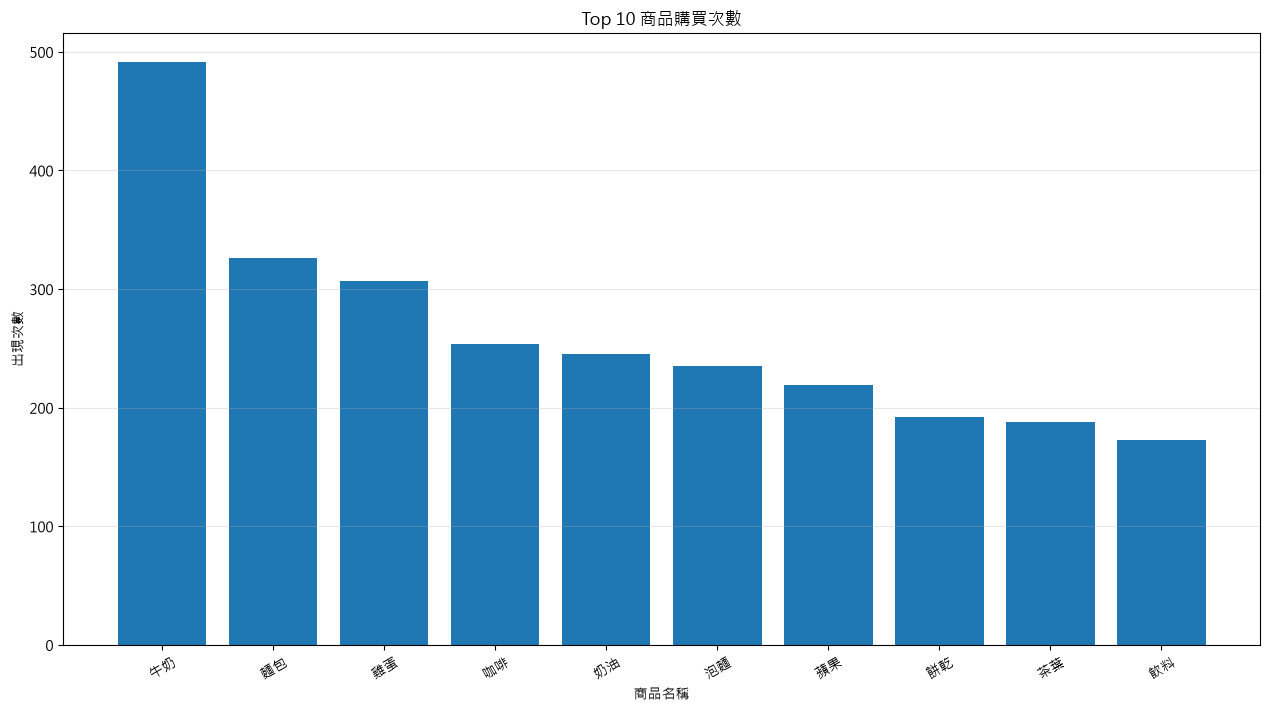

In [11]:
import matplotlib.pyplot as plt


### 設定中文字型 (Windows)
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei"]
plt.rcParams["axes.unicode_minus"] = False


### 統計商品出現次數
item_counts = df["item"].value_counts().head(10)


### 建立圖表
plt.figure(figsize=(12.8, 7.2))


### 繪製長條圖
plt.bar(
    item_counts.index,
    item_counts.values
)


### 設定圖表資訊
plt.title("Top 10 商品購買次數")
plt.xlabel("商品名稱")
plt.ylabel("出現次數")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)


### 顯示圖表
plt.tight_layout()
plt.show()

#### Top 10 Lift 關聯規則

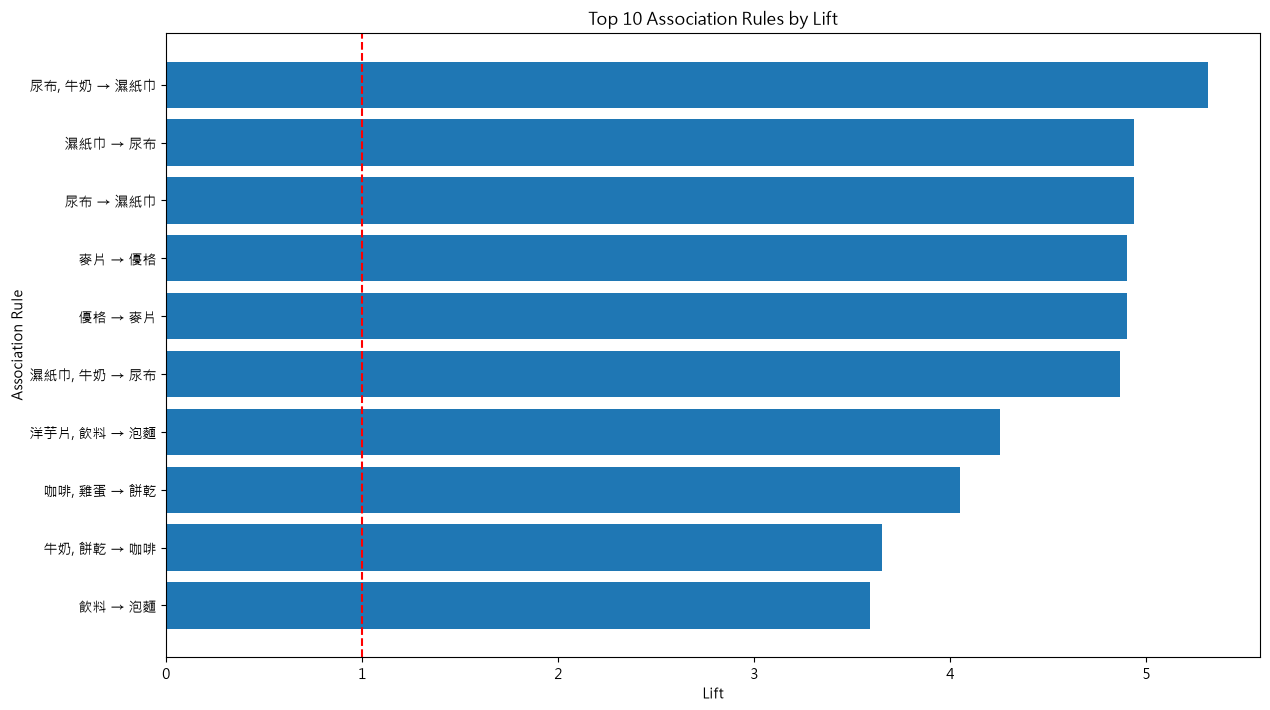

In [14]:
import matplotlib.pyplot as plt


### 取得 Lift 最高的 10 條規則
top_rules = display_rules.nlargest(
    10,
    "lift"
).sort_values("lift")


### 建立圖表
plt.figure(figsize=(12.8, 7.2))


### 繪製水平長條圖
plt.barh(
    top_rules["rule"],
    top_rules["lift"]
)


### 設定圖表資訊
plt.title("Top 10 Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Association Rule")
plt.axvline(x=1, linestyle="--", color="red")


### 顯示圖表
plt.tight_layout()
plt.show()

## 作業：使用 Apriori 分析圖書館借閱關聯

本次作業使用模擬圖書館借閱紀錄，並使用 Apriori Algorithm (Apriori 演算法) 分析讀者在同一次借閱中，哪些書籍類別經常一起出現。

例如：

- 借閱 Python 程式設計的讀者，是否也經常借閱人工智慧？
- 借閱投資理財的讀者，是否也會借閱商業管理？
- 借閱心理學的讀者，是否也會借閱自我成長？

學生需要透過 Support、Confidence、Lift 三個指標找出關聯規則，並解釋這些規則能如何協助圖書館規劃書籍推薦。

本次作業不需要預測讀者下一次一定會借哪一本書，而是找出不同書籍類別在同一次借閱紀錄中的關聯。

$$\boxed{ \text{圖書館借閱紀錄} \longrightarrow \text{Apriori} \longrightarrow \text{書籍類別關聯規則} }$$

### 資料集說明

"./data/library_borrowing_apriori_assignment.csv"

| 欄位          | 說明        |
| ----------- | --------- |
| `borrow_id` | 每次借閱的紀錄編號 |
| `category`  | 該次借閱的書籍類別 |

同一個 `borrow_id` 可以對應多種書籍類別。

例如：

| borrow_id | category   |
| --------- | ---------- |
| B0001     | Python程式設計 |
| B0001     | 人工智慧       |
| B0001     | 資料科學       |
| B0002     | 投資理財       |
| B0002     | 商業管理       |

### 作業目標

學生需要完成以下分析：

\\[ \boxed{ \text{借閱書籍類別 A} \rightarrow \text{借閱書籍類別 B} } \\]

透過 Apriori 尋找頻繁書籍類別組合，並利用關聯規則分析讀者的共同借閱行為。學生必須按照以下順序完成：

```
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
   head / info / describe
        ↓
3. 資料清理
   dropna / drop_duplicates
        ↓
4. 選擇分析欄位
   borrow_id / category
        ↓
5. One-Hot Encoding
        ↓
6. 建立 Apriori
        ↓
7. 找出 Frequent Itemsets
        ↓
8. 產生 Association Rules
        ↓
9. 評估關聯規則
   Support / Confidence / Lift
        ↓
10. 視覺化分析結果
        ↓
11. 解釋分析結果
```

### 模型與參數要求

| 項目              | 指定設定         |
| --------------- | ------------ |
| 演算法             | Apriori      |
| `min_support`   | 0.05         |
| `use_colnames`  | True         |
| `max_len`       | 3            |
| `metric`        | confidence   |
| `min_threshold` | 0.5          |
| 規則篩選            | Lift > 1     |
| 視覺化             | Scatter Plot |

學生必須自行使用 `mlxtend` 完成 Apriori 與 Association Rules，不可以直接使用已經計算好的關聯規則。